# NetShield — Dataset Comparison
## UNSW-NB15 vs CICIDS2017

**Project:** Investigating Dataset-Dependent Behavior in Machine Learning-Based Network Intrusion Detection  
**Course:** CS-245 Machine Learning — Fall 2026

### Research question

> **How different are UNSW-NB15 and CICIDS2017, and how could those differences contribute to poor cross-dataset generalization?**

This notebook is the bridge between EDA and ML experiments. It compares:

- dataset size and structure
- feature-space overlap
- data quality
- class/attack distributions
- class imbalance
- numerical feature behavior
- skewness and zero-heavy behavior
- correlation structure
- candidate semantic feature mappings
- distribution shift using KS statistics
- implications for preprocessing and cross-dataset experiments

### Methodological rule

This notebook is **exploratory**. It does not perform final scaling, SMOTE, feature selection, or train/test fitting. Those decisions belong in the preprocessing/modeling stage and must be based on training data only.

In [1]:
# ============================================================
# 1. Imports and configuration
# ============================================================

from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42
MAX_PLOT_SAMPLE = 100_000
MAX_KS_SAMPLE = 50_000

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Automatically locate the NetShield project

Expected structure:

```text
NetShield/
├── data/
│   └── raw/
│       ├── UNSW-NB15/
│       └── CICIDS2017/
└── notebooks/
```

The code searches upward from the current working directory so the notebook can be run from the `notebooks` folder without hard-coded Windows paths.

In [2]:
# ============================================================
# 2. Project path detection
# ============================================================

def find_project_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "raw").exists():
            return p
    return Path.cwd()

PROJECT_ROOT = find_project_root()
RAW_ROOT = PROJECT_ROOT / "data" / "raw"
UNSW_DIR = RAW_ROOT / "UNSW-NB15"
CICIDS_DIR = RAW_ROOT / "CICIDS2017"

print("Project root :", PROJECT_ROOT)
print("Raw root     :", RAW_ROOT)
print("UNSW folder  :", UNSW_DIR)
print("CICIDS folder:", CICIDS_DIR)

if not RAW_ROOT.exists():
    raise FileNotFoundError(
        "data/raw was not found. Open this notebook from the NetShield project "
        "or change PROJECT_ROOT manually."
    )

Project root : c:\Users\BISMILLAH\Documents\NetShield
Raw root     : c:\Users\BISMILLAH\Documents\NetShield\data\raw
UNSW folder  : c:\Users\BISMILLAH\Documents\NetShield\data\raw\UNSW-NB15
CICIDS folder: c:\Users\BISMILLAH\Documents\NetShield\data\raw\CICIDS2017


In [3]:

# ============================================================
# 1B. Output management
# ============================================================
# Every important comparison result is saved under:
# NetShield/outputs/dataset_comparison/
#
# Raw datasets are never modified.

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "dataset_comparison"
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"

for folder in [OUTPUT_DIR, PLOT_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

def save_csv(df, filename, index=False):
    """Save a DataFrame as CSV in the dataset-comparison output folder."""
    path = TABLE_DIR / filename
    df.to_csv(path, index=index)
    print("Saved:", path)

def save_text(text, filename):
    """Save text/notes in the dataset-comparison output folder."""
    path = OUTPUT_DIR / filename
    path.write_text(str(text), encoding="utf-8")
    print("Saved:", path)

print("Dataset-comparison output directory:", OUTPUT_DIR)
print("Tables:", TABLE_DIR)
print("Plots :", PLOT_DIR)


Dataset-comparison output directory: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison
Tables: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables
Plots : c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\plots


## 3. Inventory the raw files

We intentionally inspect the files before loading them. This prevents accidentally concatenating duplicate versions of the same dataset.

In [4]:
# ============================================================
# 3. File inventory
# ============================================================

def list_csvs(folder):
    if not folder.exists():
        return []
    return sorted([p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() == ".csv"])

unsw_files = list_csvs(UNSW_DIR)
cicids_files = list_csvs(CICIDS_DIR)

print(f"UNSW CSV files found: {len(unsw_files)}")
for p in unsw_files:
    print(" ", p.relative_to(PROJECT_ROOT))

print(f"\nCICIDS2017 CSV files found: {len(cicids_files)}")
for p in cicids_files:
    print(" ", p.relative_to(PROJECT_ROOT))

if not cicids_files:
    raise FileNotFoundError("No CICIDS2017 CSV files found.")

UNSW CSV files found: 9
  data\raw\UNSW-NB15\NUSW-NB15_features.csv
  data\raw\UNSW-NB15\NUSW-NB15_GT.csv
  data\raw\UNSW-NB15\Training and Testing Sets\UNSW_NB15_testing-set.csv
  data\raw\UNSW-NB15\Training and Testing Sets\UNSW_NB15_training-set.csv
  data\raw\UNSW-NB15\UNSW-NB15_1.csv
  data\raw\UNSW-NB15\UNSW-NB15_2.csv
  data\raw\UNSW-NB15\UNSW-NB15_3.csv
  data\raw\UNSW-NB15\UNSW-NB15_4.csv
  data\raw\UNSW-NB15\UNSW-NB15_LIST_EVENTS.csv

CICIDS2017 CSV files found: 8
  data\raw\CICIDS2017\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  data\raw\CICIDS2017\Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  data\raw\CICIDS2017\Friday-WorkingHours-Morning.pcap_ISCX.csv
  data\raw\CICIDS2017\Monday-WorkingHours.pcap_ISCX.csv
  data\raw\CICIDS2017\Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  data\raw\CICIDS2017\Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  data\raw\CICIDS2017\Tuesday-WorkingHours.pcap_ISCX.csv
  data\raw\CICIDS2017\Wednesday-working

# 4. Select the correct UNSW-NB15 source

If the standard `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv` files are present, they are preferred.

If they are not available, the code falls back to the numbered UNSW-NB15 files.

This avoids silently mixing multiple representations of the same data.

In [5]:
# ============================================================
# 4. UNSW source selection
# ============================================================

def norm_filename(path):
    return re.sub(r"[^a-z0-9]", "", path.name.lower())

def first_match(paths, tokens):
    for p in paths:
        name = norm_filename(p)
        if any(t in name for t in tokens):
            return p
    return None

unsw_train = first_match(
    unsw_files,
    ["unswnb15trainingset", "trainingset"]
)
unsw_test = first_match(
    unsw_files,
    ["unswnb15testingset", "testingset"]
)

if unsw_train and unsw_test:
    UNSW_SOURCE_FILES = [unsw_train, unsw_test]
    UNSW_SOURCE_MODE = "training/testing split"
else:
    numbered = [
        p for p in unsw_files
        if re.search(r"unsw[-_]?nb15[_-]?[1-4]", p.name.lower())
    ]
    if not numbered:
        raise FileNotFoundError(
            "Could not identify UNSW training/testing files or numbered UNSW files."
        )
    UNSW_SOURCE_FILES = sorted(numbered)
    UNSW_SOURCE_MODE = "numbered UNSW-NB15 files"

print("UNSW source mode:", UNSW_SOURCE_MODE)
for p in UNSW_SOURCE_FILES:
    print(" ", p)

UNSW source mode: training/testing split
  c:\Users\BISMILLAH\Documents\NetShield\data\raw\UNSW-NB15\Training and Testing Sets\UNSW_NB15_training-set.csv
  c:\Users\BISMILLAH\Documents\NetShield\data\raw\UNSW-NB15\Training and Testing Sets\UNSW_NB15_testing-set.csv


# 5. Load both datasets

CICIDS2017 is distributed over multiple CSV files. We keep a `source_file` metadata column so later analysis can identify differences between capture periods.

The raw files themselves are never modified.

In [6]:
# ============================================================
# 5. Loading
# ============================================================

def read_clean(path):
    df = pd.read_csv(path, low_memory=False)
    df.columns = (
        df.columns.astype(str)
        .str.replace("\ufeff", "", regex=False)
        .str.strip()
    )
    return df

def load_many(paths):
    frames, meta = [], []
    for path in paths:
        print("Loading:", path.name)
        df = read_clean(path)
        df["source_file"] = path.name
        frames.append(df)
        meta.append({
            "source_file": path.name,
            "rows": len(df),
            "features_before_metadata": len(df.columns) - 1,
            "memory_MB": df.memory_usage(deep=True).sum() / 1024**2
        })
    return pd.concat(frames, ignore_index=True, sort=False), pd.DataFrame(meta)

UNSW, unsw_file_summary = load_many(UNSW_SOURCE_FILES)
CICIDS, cicids_file_summary = load_many(cicids_files)

print("\nUNSW shape  :", UNSW.shape)
print("CICIDS shape:", CICIDS.shape)

Loading: UNSW_NB15_training-set.csv
Loading: UNSW_NB15_testing-set.csv
Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv

UNSW shape  : (257673, 46)
CICIDS shape: (2830743, 80)


# 6. High-level structural comparison

The first comparison establishes how different the datasets are before any ML preprocessing.

In [7]:
# ============================================================
# 6. High-level profile
# ============================================================

def profile(df, name):
    numeric = df.select_dtypes(include=np.number)
    return {
        "Dataset": name,
        "Rows": len(df),
        "Columns including metadata": df.shape[1],
        "Numerical columns": numeric.shape[1],
        "Non-numerical columns": df.shape[1] - numeric.shape[1],
        "Missing cells": int(df.isna().sum().sum()),
        "Infinite numeric cells": int(np.isinf(numeric).sum().sum()),
        "Duplicate rows": int(df.duplicated().sum()),
        "Memory (MB)": df.memory_usage(deep=True).sum() / 1024**2
    }

profile_table = pd.DataFrame([
    profile(UNSW, "UNSW-NB15"),
    profile(CICIDS, "CICIDS2017")
]).set_index("Dataset")

display(profile_table)

print("UNSW file composition")
display(unsw_file_summary)

print("CICIDS2017 file composition")
display(cicids_file_summary)

,Rows,Columns including metadata,Numerical columns,Non-numerical columns,Missing cells,Infinite numeric cells,Duplicate rows,Memory (MB)
Dataset,,,,,,,,
UNSW-NB15,257673,46,41,5,0,0,0,150.8799
CICIDS2017,2830743,80,78,2,1358,4376,256479,"2,078.1377"


UNSW file composition


,source_file,rows,features_before_metadata,memory_MB
0,UNSW_NB15_training-set.csv,175341,45,102.7468
1,UNSW_NB15_testing-set.csv,82332,45,48.1332


CICIDS2017 file composition


,source_file,rows,features_before_metadata,memory_MB
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,166.8188
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79,213.3963
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,140.0934
3,Monday-WorkingHours.pcap_ISCX.csv,529918,79,384.5861
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79,216.6082
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79,127.1673
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,324.1081
7,Wednesday-workingHours.pcap_ISCX.csv,692703,79,505.3091


# 7. Label and attack-distribution comparison

The datasets use different label schemas. We standardize labels **only for analysis**, preserving the original columns.

This section answers:

- How many classes exist?
- How dominant is benign traffic?
- Which attack types dominate?
- Which classes are rare?
- How different are the attack distributions?

In [8]:
# ============================================================
# 7. Label identification and normalization
# ============================================================

def find_col(df, candidates):
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

unsw_label_col = find_col(UNSW, ["label", "class", "attack_cat"])
unsw_attack_col = find_col(UNSW, ["attack_cat"])
cicids_label_col = find_col(CICIDS, ["label", "class", "target"])

print("UNSW label :", unsw_label_col)
print("UNSW attack:", unsw_attack_col)
print("CICIDS label:", cicids_label_col)

if not unsw_label_col or not cicids_label_col:
    raise ValueError("Could not identify one or both label columns.")

UNSW["__label_clean__"] = (
    UNSW[unsw_label_col].astype(str).str.strip().str.lower()
)
CICIDS["__label_clean__"] = (
    CICIDS[cicids_label_col].astype(str).str.strip().str.lower()
)

print("\nUNSW labels")
display(UNSW["__label_clean__"].value_counts().to_frame("count"))

print("\nCICIDS labels")
display(CICIDS["__label_clean__"].value_counts().to_frame("count"))

UNSW label : label
UNSW attack: attack_cat
CICIDS label: Label

UNSW labels


,count
__label_clean__,
1,164673
0,93000



CICIDS labels


,count
__label_clean__,
benign,2273097
dos hulk,231073
portscan,158930
ddos,128027
dos goldeneye,10293
ftp-patator,7938
ssh-patator,5897
dos slowloris,5796
dos slowhttptest,5499


Counts


,UNSW-NB15,CICIDS2017
__binary_label__,,
Attack,257673,557646
Benign,0,2273097


Percentages


,UNSW-NB15,CICIDS2017
__binary_label__,,
Attack,100.0000,19.7000
Benign,0.0000,80.3000


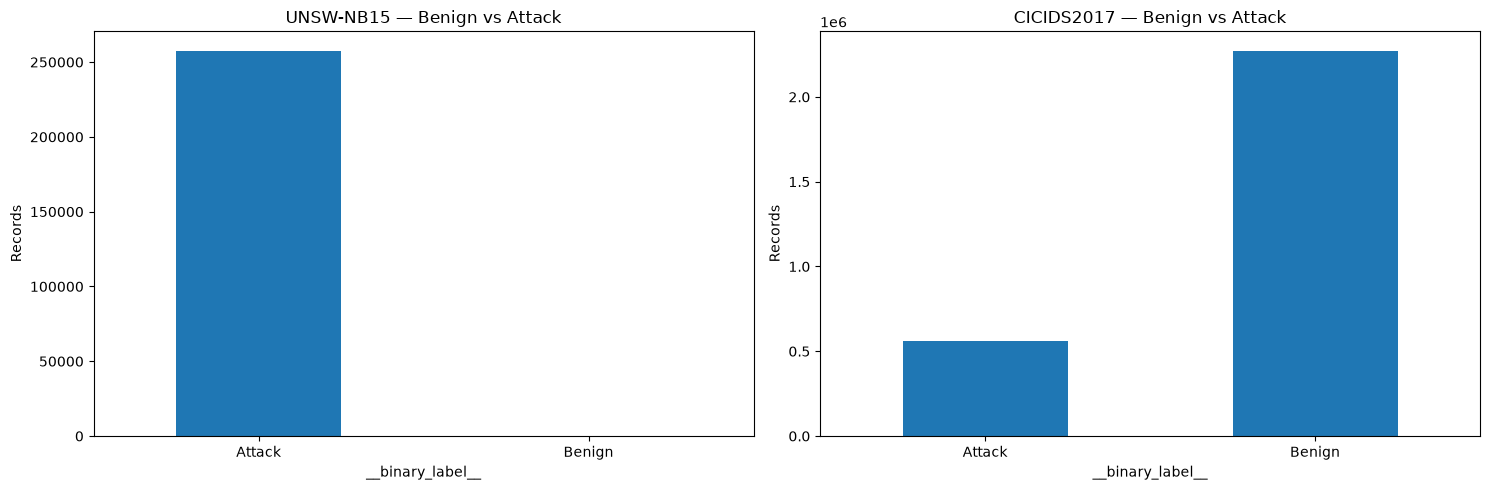

In [9]:
# ============================================================
# 8. Binary benign-vs-attack comparison
# ============================================================

def binary_label(x):
    x = str(x).strip().lower()
    return "Benign" if x in {
        "normal", "benign", "normal traffic", "benign traffic"
    } else "Attack"

UNSW["__binary_label__"] = UNSW["__label_clean__"].map(binary_label)
CICIDS["__binary_label__"] = CICIDS["__label_clean__"].map(binary_label)

binary_counts = pd.DataFrame({
    "UNSW-NB15": UNSW["__binary_label__"].value_counts(),
    "CICIDS2017": CICIDS["__binary_label__"].value_counts()
}).fillna(0).astype(int)

binary_percent = binary_counts.div(binary_counts.sum(axis=0), axis=1) * 100

print("Counts")
display(binary_counts)

print("Percentages")
display(binary_percent.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

binary_counts["UNSW-NB15"].plot.bar(ax=axes[0])
axes[0].set_title("UNSW-NB15 — Benign vs Attack")
axes[0].set_ylabel("Records")
axes[0].tick_params(axis="x", rotation=0)

binary_counts["CICIDS2017"].plot.bar(ax=axes[1])
axes[1].set_title("CICIDS2017 — Benign vs Attack")
axes[1].set_ylabel("Records")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(PLOT_DIR / "01_binary_benign_vs_attack.png", dpi=200, bbox_inches="tight")
plt.show()

,UNSW count,CICIDS count,UNSW %,CICIDS %
__label_clean__,,,,
1,164673,0,63.9077,0.0000
0,93000,0,36.0923,0.0000
benign,0,2273097,0.0000,80.3004
dos hulk,0,231073,0.0000,8.1630
portscan,0,158930,0.0000,5.6144
ddos,0,128027,0.0000,4.5227
dos goldeneye,0,10293,0.0000,0.3636
ftp-patator,0,7938,0.0000,0.2804
ssh-patator,0,5897,0.0000,0.2083


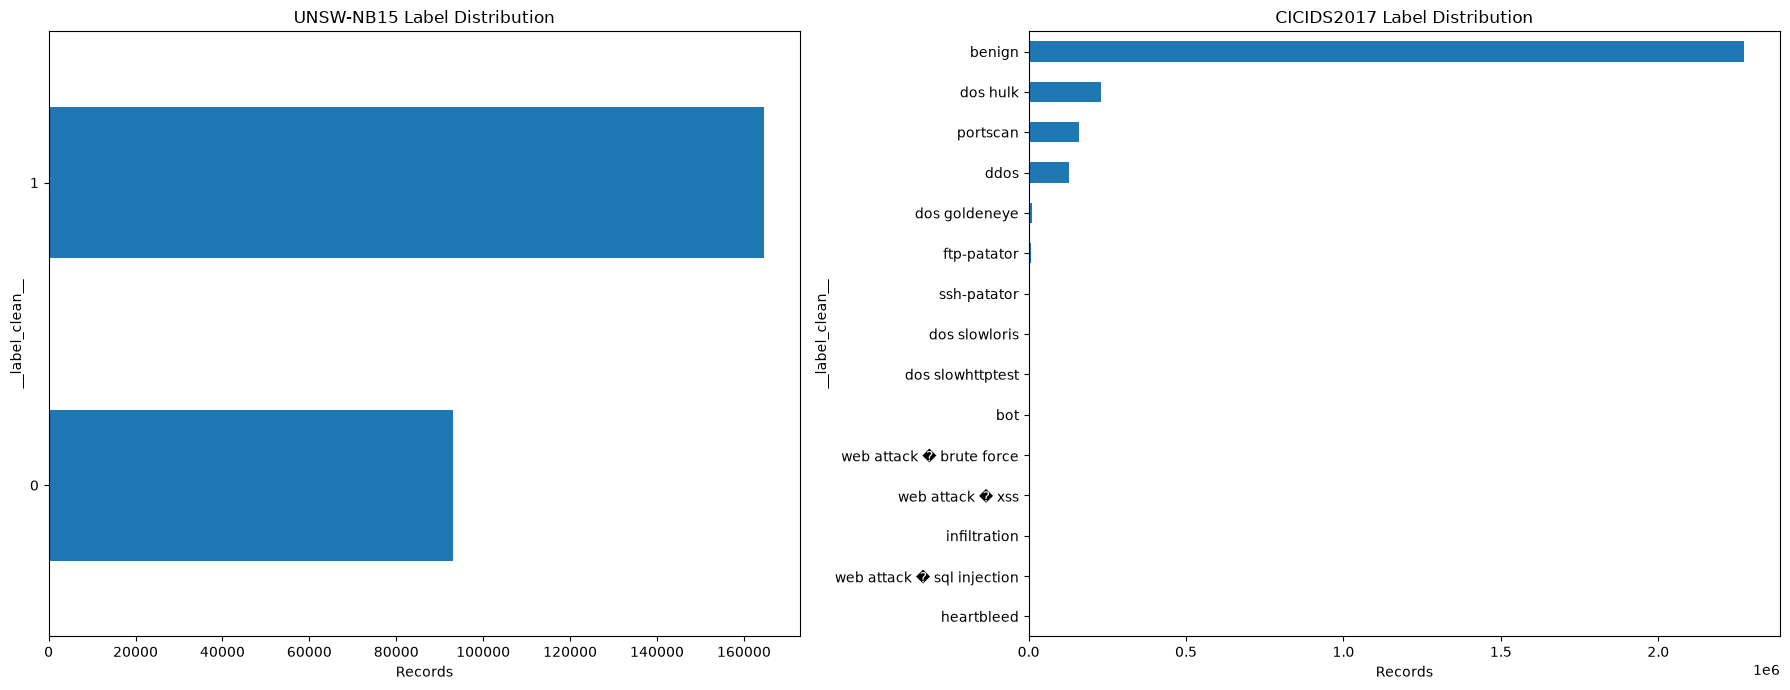

In [10]:
# ============================================================
# 9. Multi-class distribution comparison
# ============================================================

unsw_counts = UNSW["__label_clean__"].value_counts()
cicids_counts = CICIDS["__label_clean__"].value_counts()

attack_distribution = pd.concat([
    unsw_counts.rename("UNSW count"),
    cicids_counts.rename("CICIDS count")
], axis=1).fillna(0).astype(int)

attack_distribution["UNSW %"] = (
    attack_distribution["UNSW count"] / attack_distribution["UNSW count"].sum() * 100
)
attack_distribution["CICIDS %"] = (
    attack_distribution["CICIDS count"] / attack_distribution["CICIDS count"].sum() * 100
)

display(attack_distribution.sort_values("UNSW count", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

unsw_counts.sort_values().plot.barh(ax=axes[0])
axes[0].set_title("UNSW-NB15 Label Distribution")
axes[0].set_xlabel("Records")

cicids_counts.sort_values().plot.barh(ax=axes[1])
axes[1].set_title("CICIDS2017 Label Distribution")
axes[1].set_xlabel("Records")

plt.tight_layout()
plt.savefig(PLOT_DIR / "02_multiclass_label_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# 10. Quantify class imbalance

We report the majority/minority ratio because class imbalance is central to the choice of metrics and later modeling strategy.

We do **not** apply SMOTE or delete majority samples here.

In [11]:
# ============================================================
# 10. Imbalance metrics
# ============================================================

def imbalance(series):
    c = series.value_counts()
    return {
        "Number of classes": len(c),
        "Majority class": c.index[0],
        "Majority count": int(c.iloc[0]),
        "Minority class": c.index[-1],
        "Minority count": int(c.iloc[-1]),
        "Majority/minority ratio": c.iloc[0] / c.iloc[-1],
        "Minority share (%)": c.iloc[-1] / c.sum() * 100
    }

imbalance_table = pd.DataFrame([
    {"Dataset": "UNSW-NB15", **imbalance(UNSW["__label_clean__"])},
    {"Dataset": "CICIDS2017", **imbalance(CICIDS["__label_clean__"])}
]).set_index("Dataset")

display(imbalance_table)

,Number of classes,Majority class,Majority count,Minority class,Minority count,Majority/minority ratio,Minority share (%)
Dataset,,,,,,,
UNSW-NB15,2,1,164673,0,93000,1.7707,36.0923
CICIDS2017,15,benign,2273097,heartbleed,11,"206,645.1818",0.0004


# 11. Feature-space comparison

Exact column-name overlap is only a first diagnostic.

A feature may represent the same traffic concept under a completely different name. Therefore we report:

1. exact shared names
2. dataset-specific features
3. normalized-name overlap
4. candidate semantic mappings for later verification

In [12]:
# ============================================================
# 11. Feature-space overlap
# ============================================================

META = {"source_file", "__label_clean__", "__binary_label__"}

unsw_features = [c for c in UNSW.columns if c not in META]
cicids_features = [c for c in CICIDS.columns if c not in META]

unsw_set = set(unsw_features)
cicids_set = set(cicids_features)

exact_shared = sorted(unsw_set & cicids_set)
unsw_only = sorted(unsw_set - cicids_set)
cicids_only = sorted(cicids_set - unsw_set)

feature_summary = pd.DataFrame({
    "UNSW-NB15": [
        len(unsw_features),
        len(unsw_only),
        len(exact_shared)
    ],
    "CICIDS2017": [
        len(cicids_features),
        len(cicids_only),
        len(exact_shared)
    ]
}, index=[
    "Total feature columns",
    "Dataset-specific feature columns",
    "Exact shared names"
])

display(feature_summary)

print(f"Exact shared feature names ({len(exact_shared)}):")
print(exact_shared)

,UNSW-NB15,CICIDS2017
Total feature columns,45,79
Dataset-specific feature columns,45,79
Exact shared names,0,0


Exact shared feature names (0):
[]


In [13]:
# ============================================================
# 12. Normalized-name overlap
# ============================================================

def normalize_feature_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

u_norm = {normalize_feature_name(c): c for c in unsw_features}
c_norm = {normalize_feature_name(c): c for c in cicids_features}

shared_norm = sorted(set(u_norm) & set(c_norm))

normalized_overlap = pd.DataFrame([
    {
        "Normalized name": k,
        "UNSW feature": u_norm[k],
        "CICIDS feature": c_norm[k]
    }
    for k in shared_norm
])

display(normalized_overlap)

,Normalized name,UNSW feature,CICIDS feature
0,label,label,Label


# 13. Candidate semantic feature alignment

This is one of the most important sections for NetShield.

**Do not assume these mappings are automatically valid.**

They are candidate concepts to investigate before constructing the common semantic feature space. The exact definition, units, direction, and aggregation must be verified before modeling.

In [14]:
# ============================================================
# 13. Candidate semantic mapping
# ============================================================

semantic_candidates = pd.DataFrame([
    ["Flow duration", "dur", "Flow Duration", "High"],
    ["Source/forward packet count", "spkts", "Total Fwd Packets", "High"],
    ["Destination/backward packet count", "dpkts", "Total Backward Packets", "High"],
    ["Source/forward bytes", "sbytes", "Total Length of Fwd Packets", "Medium-High"],
    ["Destination/backward bytes", "dbytes", "Total Length of Bwd Packets", "Medium-High"],
    ["Overall packet rate", "rate", "Flow Packets/s", "Medium-High"],
    ["Forward packet rate", "sload", "Fwd Packets/s", "Medium"],
    ["Backward packet rate", "dload", "Bwd Packets/s", "Medium"],
    ["Transport protocol", "proto", "Protocol", "Medium"],
], columns=[
    "Semantic concept",
    "UNSW candidate",
    "CICIDS candidate",
    "Initial confidence"
])

semantic_candidates["UNSW present"] = semantic_candidates["UNSW candidate"].isin(UNSW.columns)
semantic_candidates["CICIDS present"] = semantic_candidates["CICIDS candidate"].isin(CICIDS.columns)

display(semantic_candidates)

,Semantic concept,UNSW candidate,CICIDS candidate,Initial confidence,UNSW present,CICIDS present
0,Flow duration,dur,Flow Duration,High,True,True
1,Source/forward packet count,spkts,Total Fwd Packets,High,True,True
2,Destination/backward packet count,dpkts,Total Backward Packets,High,True,True
3,Source/forward bytes,sbytes,Total Length of Fwd Packets,Medium-High,True,True
4,Destination/backward bytes,dbytes,Total Length of Bwd Packets,Medium-High,True,True
5,Overall packet rate,rate,Flow Packets/s,Medium-High,True,True
6,Forward packet rate,sload,Fwd Packets/s,Medium,True,True
7,Backward packet rate,dload,Bwd Packets/s,Medium,True,True
8,Transport protocol,proto,Protocol,Medium,True,False


### Why semantic alignment matters

A direct column-name intersection may leave very few usable features.

Instead, we can later construct a smaller set of **semantically justified common variables**. That experiment will test whether reducing dataset-specific representation differences improves transfer.

Again: this table is a **candidate mapping**, not the final feature-selection decision.

# 14. Numerical distribution comparison

Network-flow variables commonly have extreme right skew.

For each dataset we quantify:

- mean
- median
- standard deviation
- minimum/maximum
- skewness
- zero percentage
- missing percentage
- infinite percentage

The purpose is to discover distribution mismatch before deciding how preprocessing should handle it.

In [15]:
# ============================================================
# 14. Numerical statistics
# ============================================================

def numerical_stats(df, dataset_name):
    cols = [
        c for c in df.select_dtypes(include=np.number).columns
        if not c.startswith("__")
    ]

    rows = []
    for col in cols:
        s = pd.to_numeric(df[col], errors="coerce")
        finite = s.replace([np.inf, -np.inf], np.nan)

        rows.append({
            "Dataset": dataset_name,
            "Feature": col,
            "Mean": finite.mean(),
            "Median": finite.median(),
            "Std": finite.std(),
            "Min": finite.min(),
            "Max": finite.max(),
            "Skewness": finite.skew(),
            "Zero %": (finite == 0).mean() * 100,
            "Missing %": s.isna().mean() * 100,
            "Infinite %": np.isinf(s).mean() * 100
        })

    return pd.DataFrame(rows)

UNSW_STATS = numerical_stats(UNSW, "UNSW-NB15")
CICIDS_STATS = numerical_stats(CICIDS, "CICIDS2017")

print("UNSW numerical statistics")
display(UNSW_STATS)

print("CICIDS numerical statistics")
display(CICIDS_STATS)

UNSW numerical statistics


,Dataset,Feature,Mean,Median,Std,Min,Max,Skewness,Zero %,Missing %,Infinite %
0,UNSW-NB15,id,"72,811.8239","64,419.0000","48,929.9176",1.0000,"175,341.0000",0.4498,0.0000,0.0000,0.0000
1,UNSW-NB15,dur,1.2467,0.0043,5.9743,0.0000,60.0000,8.0225,1.3998,0.0000,0.0000
2,UNSW-NB15,spkts,19.7771,4.0000,135.9472,1.0000,"10,646.0000",42.5219,0.0000,0.0000,0.0000
3,UNSW-NB15,dpkts,18.5147,2.0000,111.9860,0.0000,"11,018.0000",41.1928,46.6824,0.0000,0.0000
4,UNSW-NB15,sbytes,"8,572.9518",528.0000,"173,773.8806",24.0000,"14,355,774.0000",47.9172,0.0000,0.0000,0.0000
5,UNSW-NB15,dbytes,"14,387.2875",178.0000,"146,199.2819",0.0000,"14,657,531.0000",44.3402,46.6824,0.0000,0.0000
6,UNSW-NB15,rate,"91,253.9124","2,955.6649","160,344.6367",0.0000,"1,000,000.0030",3.3805,1.5399,0.0000,0.0000
7,UNSW-NB15,sttl,180.0009,254.0000,102.4883,0.0000,255.0000,-0.6822,1.6339,0.0000,0.0000
8,UNSW-NB15,dttl,84.7550,29.0000,112.7621,0.0000,254.0000,0.7872,46.7410,0.0000,0.0000
9,UNSW-NB15,sload,"70,608,691.2282","743,942.3125","185,731,252.8417",0.0000,"5,988,000,256.0000",8.9333,1.5430,0.0000,0.0000


CICIDS numerical statistics


,Dataset,Feature,Mean,Median,Std,Min,Max,Skewness,Zero %,Missing %,Infinite %
0,CICIDS2017,Destination Port,"8,071.4825",80.0000,"18,283.6322",0.0000,"65,535.0000",2.0721,0.0599,0.0000,0.0000
1,CICIDS2017,Flow Duration,"14,785,663.9295","31,316.0000","33,653,744.0859",-13.0000,"119,999,998.0000",2.1554,0.1013,0.0000,0.0000
2,CICIDS2017,Total Fwd Packets,9.3612,2.0000,749.6728,1.0000,"219,759.0000",244.3806,0.0000,0.0000,0.0000
3,CICIDS2017,Total Backward Packets,10.3938,2.0000,997.3883,0.0000,"291,922.0000",244.6795,16.0212,0.0000,0.0000
4,CICIDS2017,Total Length of Fwd Packets,549.3024,62.0000,"9,993.5892",0.0000,"12,900,000.0000",805.5705,15.8676,0.0000,0.0000
5,CICIDS2017,Total Length of Bwd Packets,"16,162.6425",123.0000,"2,263,088.0517",0.0000,"655,453,030.0000",244.3309,25.0021,0.0000,0.0000
6,CICIDS2017,Fwd Packet Length Max,207.5999,37.0000,717.1848,0.0000,"24,820.0000",9.8492,15.8676,0.0000,0.0000
7,CICIDS2017,Fwd Packet Length Min,18.7137,2.0000,60.3393,0.0000,"2,325.0000",20.1392,46.5329,0.0000,0.0000
8,CICIDS2017,Fwd Packet Length Mean,58.2019,34.0000,186.0912,0.0000,"5,940.8571",9.1358,15.8676,0.0000,0.0000
9,CICIDS2017,Fwd Packet Length Std,68.9101,0.0000,281.1871,0.0000,"7,125.5968",10.5311,65.3780,0.0000,0.0000


# 15. Compare shared semantic variables

We now use the candidate mappings that are actually present in both datasets.

For each candidate we compare:

- median
- IQR
- skewness
- zero percentage
- missing/infinite behavior
- empirical distribution

In [16]:
# ============================================================
# 15. Shared semantic numerical statistics
# ============================================================

verified = semantic_candidates[
    semantic_candidates["UNSW present"] &
    semantic_candidates["CICIDS present"]
].copy()

rows = []

for _, r in verified.iterrows():
    u = pd.to_numeric(UNSW[r["UNSW candidate"]], errors="coerce")
    c = pd.to_numeric(CICIDS[r["CICIDS candidate"]], errors="coerce")

    rows.append({
        "Semantic concept": r["Semantic concept"],
        "UNSW feature": r["UNSW candidate"],
        "CICIDS feature": r["CICIDS candidate"],
        "UNSW median": u.median(),
        "CICIDS median": c.median(),
        "UNSW IQR": u.quantile(.75) - u.quantile(.25),
        "CICIDS IQR": c.quantile(.75) - c.quantile(.25),
        "UNSW skewness": u.skew(),
        "CICIDS skewness": c.skew(),
        "UNSW zero %": (u == 0).mean() * 100,
        "CICIDS zero %": (c == 0).mean() * 100
    })

semantic_stats = pd.DataFrame(rows)
display(semantic_stats)

,Semantic concept,UNSW feature,CICIDS feature,UNSW median,CICIDS median,UNSW IQR,CICIDS IQR,UNSW skewness,CICIDS skewness,UNSW zero %,CICIDS zero %
0,Flow duration,dur,Flow Duration,0.0043,"31,316.0000",0.6858,"3,204,673.5000",8.0225,2.1554,1.3998,0.1013
1,Source/forward packet count,spkts,Total Fwd Packets,4.0000,2.0000,10.0000,3.0000,42.5219,244.3806,0.0000,0.0000
2,Destination/backward packet count,dpkts,Total Backward Packets,2.0000,2.0000,10.0000,3.0000,41.1928,244.6795,46.6824,16.0212
3,Source/forward bytes,sbytes,Total Length of Fwd Packets,528.0000,62.0000,"1,248.0000",175.0000,47.9172,805.5705,0.0000,15.8676
4,Destination/backward bytes,dbytes,Total Length of Bwd Packets,178.0000,123.0000,"1,064.0000",482.0000,44.3402,244.3309,46.6824,25.0021
5,Overall packet rate,rate,Flow Packets/s,"2,955.6649",110.6684,"124,969.2110","23,252.3677",3.3805,NaN,1.5399,0.0000
6,Forward packet rate,sload,Fwd Packets/s,"743,942.3125",61.3252,"79,987,681.9951","12,046.4433",8.9333,5.6849,1.5430,0.1053
7,Backward packet rate,dload,Bwd Packets/s,"1,747.4413",19.8279,"22,105.3848","7,352.8183",4.7108,21.4890,46.6882,16.0601


# 16. KS-test: empirical distribution shift

The two-sample Kolmogorov–Smirnov statistic measures the largest vertical difference between the empirical CDFs of two samples.

- `KS ≈ 0` means the distributions are close.
- Larger `KS` means stronger distributional separation.

Because these datasets are large, p-values can become tiny even for practically small differences. We therefore focus primarily on the **KS statistic as an effect-size-like diagnostic**, together with visualizations.

In [17]:
# ============================================================
# 16. KS distribution comparison
# ============================================================

def clean_numeric_sample(df, col, n=MAX_KS_SAMPLE):
    s = pd.to_numeric(df[col], errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan).dropna()

    if len(s) > n:
        s = s.sample(n=n, random_state=RANDOM_STATE)

    return s.to_numpy()

ks_rows = []

for _, r in verified.iterrows():
    u = clean_numeric_sample(UNSW, r["UNSW candidate"])
    c = clean_numeric_sample(CICIDS, r["CICIDS candidate"])

    if len(u) >= 2 and len(c) >= 2:
        stat, p = ks_2samp(u, c)
        ks_rows.append({
            "Semantic concept": r["Semantic concept"],
            "UNSW feature": r["UNSW candidate"],
            "CICIDS feature": r["CICIDS candidate"],
            "UNSW n": len(u),
            "CICIDS n": len(c),
            "KS statistic": stat,
            "p-value": p
        })

ks_results = pd.DataFrame(ks_rows).sort_values(
    "KS statistic", ascending=False
)

display(ks_results)

,Semantic concept,UNSW feature,CICIDS feature,UNSW n,CICIDS n,KS statistic,p-value
0,Flow duration,dur,Flow Duration,50000,50000,0.9359,0.0000
3,Source/forward bytes,sbytes,Total Length of Fwd Packets,50000,50000,0.6658,0.0000
6,Forward packet rate,sload,Fwd Packets/s,50000,50000,0.5655,0.0000
1,Source/forward packet count,spkts,Total Fwd Packets,50000,50000,0.3336,0.0000
5,Overall packet rate,rate,Flow Packets/s,50000,50000,0.3322,0.0000
2,Destination/backward packet count,dpkts,Total Backward Packets,50000,50000,0.3052,0.0000
7,Backward packet rate,dload,Bwd Packets/s,50000,50000,0.3049,0.0000
4,Destination/backward bytes,dbytes,Total Length of Bwd Packets,50000,50000,0.2163,0.0000


# 17. Visualize distribution shift

Raw network-flow values can span several orders of magnitude. For readability we use `log1p` for non-negative variables where appropriate.

The log transformation here is **only for visualization**. It does not modify the dataset.

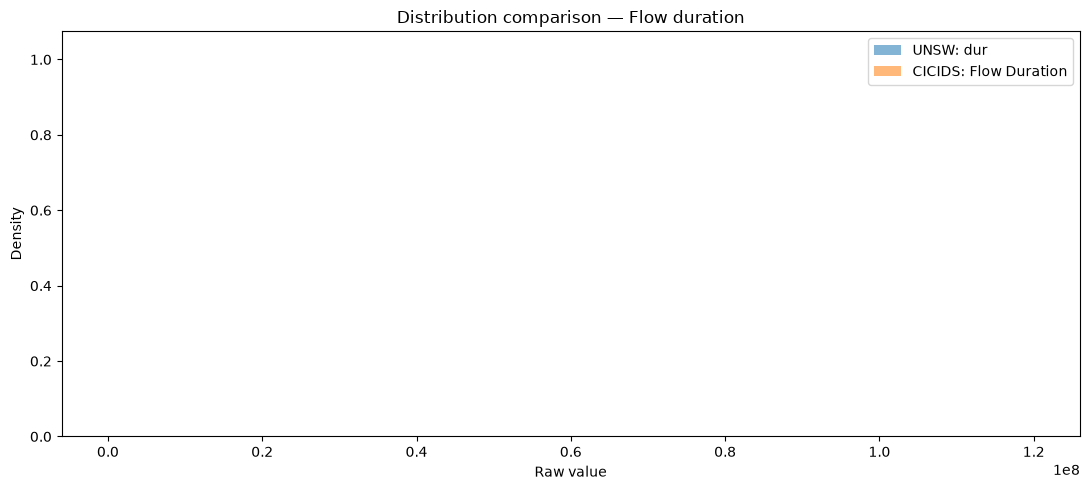

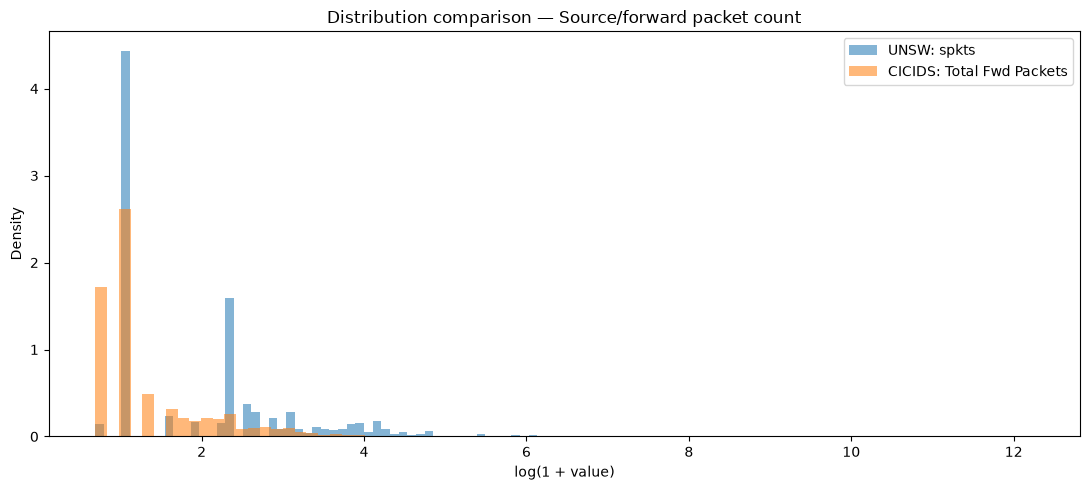

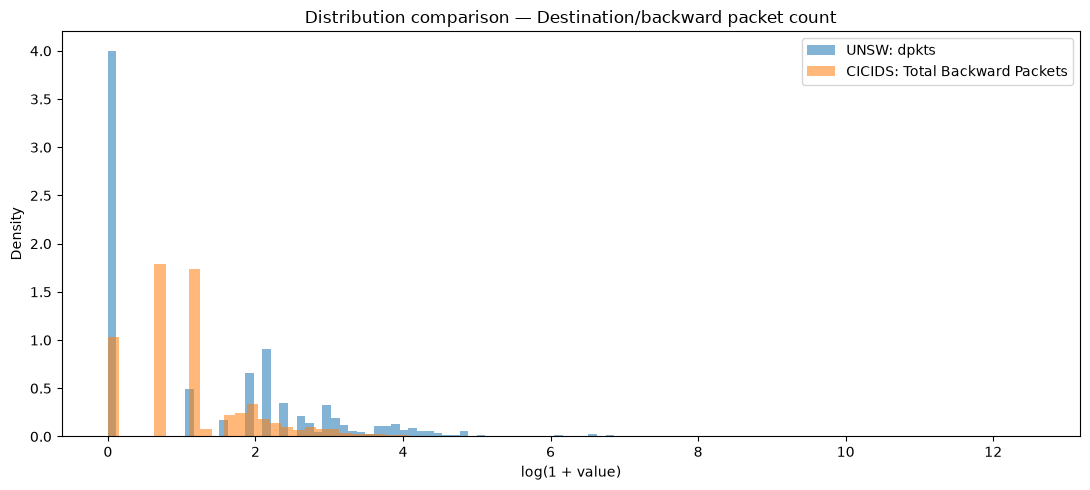

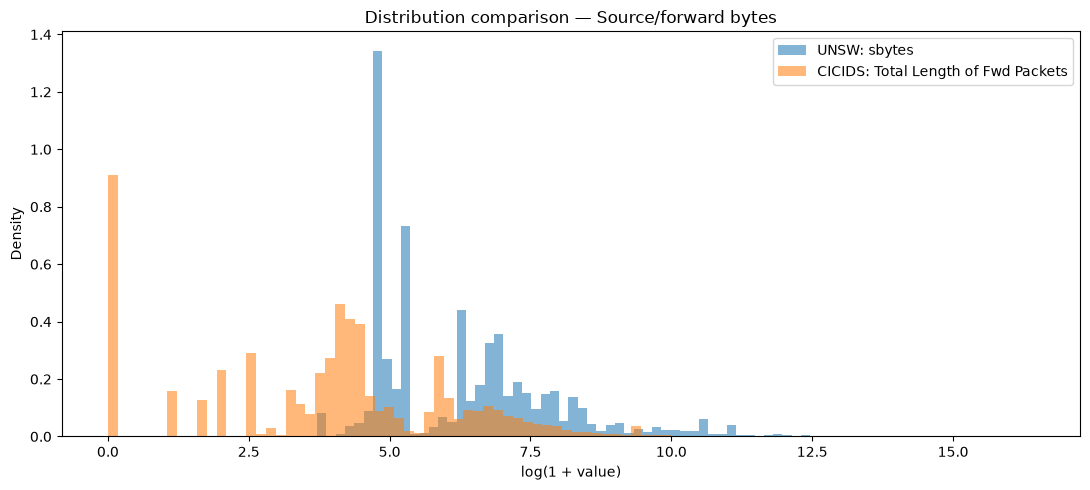

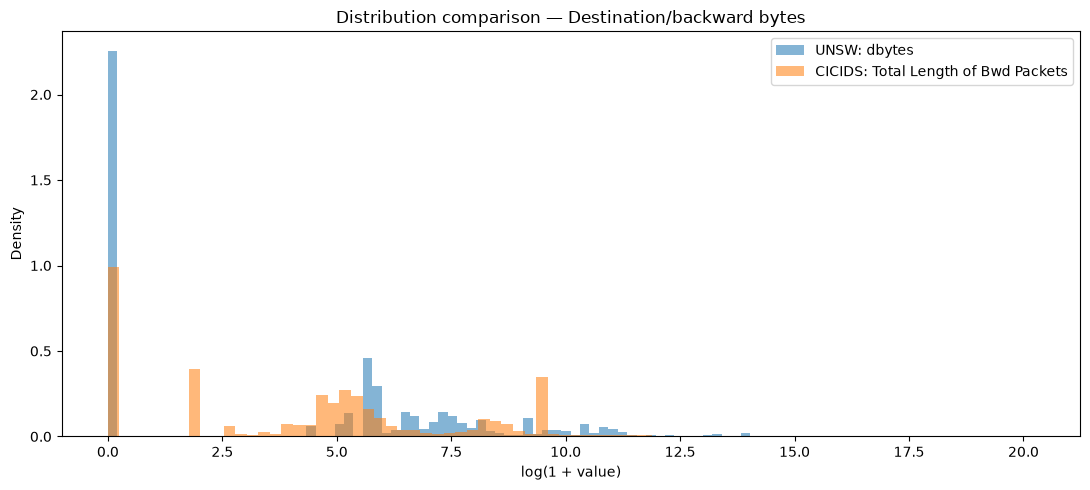

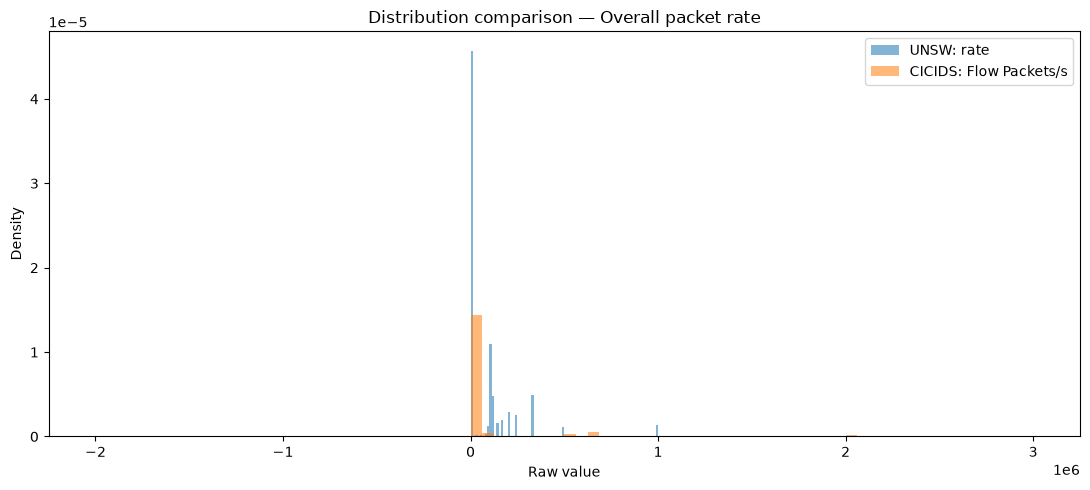

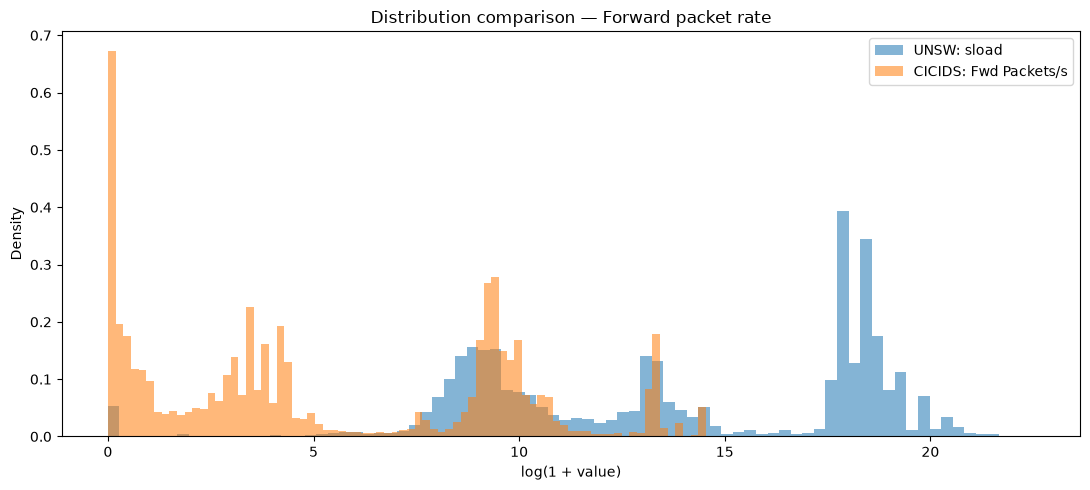

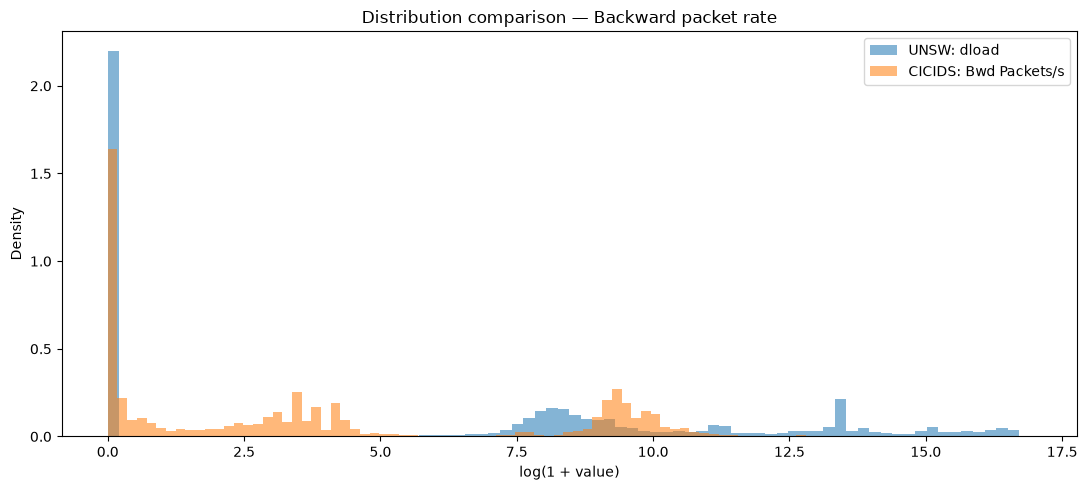

In [18]:
# ============================================================
# 17. Distribution plots for verified semantic variables
# ============================================================

def comparison_plot(u_col, c_col, concept):
    u = pd.to_numeric(UNSW[u_col], errors="coerce")
    c = pd.to_numeric(CICIDS[c_col], errors="coerce")

    u = u.replace([np.inf, -np.inf], np.nan).dropna()
    c = c.replace([np.inf, -np.inf], np.nan).dropna()

    u = u.sample(min(len(u), MAX_PLOT_SAMPLE), random_state=RANDOM_STATE)
    c = c.sample(min(len(c), MAX_PLOT_SAMPLE), random_state=RANDOM_STATE)

    # log1p visualization is valid only for non-negative observations
    if u.min() >= 0 and c.min() >= 0:
        u_plot, c_plot = np.log1p(u), np.log1p(c)
        xlabel = "log(1 + value)"
    else:
        u_plot, c_plot = u, c
        xlabel = "Raw value"

    plt.figure(figsize=(11, 5))
    plt.hist(u_plot, bins=80, density=True, alpha=.55, label=f"UNSW: {u_col}")
    plt.hist(c_plot, bins=80, density=True, alpha=.55, label=f"CICIDS: {c_col}")
    plt.title(f"Distribution comparison — {concept}")
    plt.xlabel(xlabel)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    safe_name = re.sub(r"[^A-Za-z0-9]+", "_", str(concept)).strip("_").lower()
    plt.savefig(PLOT_DIR / f"semantic_distribution_{safe_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

for _, r in verified.iterrows():
    comparison_plot(r["UNSW candidate"], r["CICIDS candidate"], r["Semantic concept"])

# 18. Zero-heavy behavior

Two variables can have similar medians but very different proportions of zero observations.

This can matter because a zero may indicate that one traffic direction is absent or that a feature is rarely active.

In [19]:
# ============================================================
# 18. Zero-rate comparison
# ============================================================

zero_rows = []

for _, r in verified.iterrows():
    u = pd.to_numeric(UNSW[r["UNSW candidate"]], errors="coerce")
    c = pd.to_numeric(CICIDS[r["CICIDS candidate"]], errors="coerce")

    uz = (u == 0).mean() * 100
    cz = (c == 0).mean() * 100

    zero_rows.append({
        "Semantic concept": r["Semantic concept"],
        "UNSW feature": r["UNSW candidate"],
        "UNSW zero %": uz,
        "CICIDS feature": r["CICIDS candidate"],
        "CICIDS zero %": cz,
        "Absolute difference (pp)": abs(uz - cz)
    })

zero_comparison = pd.DataFrame(zero_rows).sort_values(
    "Absolute difference (pp)", ascending=False
)

display(zero_comparison)

,Semantic concept,UNSW feature,UNSW zero %,CICIDS feature,CICIDS zero %,Absolute difference (pp)
2,Destination/backward packet count,dpkts,46.6824,Total Backward Packets,16.0212,30.6612
7,Backward packet rate,dload,46.6882,Bwd Packets/s,16.0601,30.6281
4,Destination/backward bytes,dbytes,46.6824,Total Length of Bwd Packets,25.0021,21.6803
3,Source/forward bytes,sbytes,0.0000,Total Length of Fwd Packets,15.8676,15.8676
5,Overall packet rate,rate,1.5399,Flow Packets/s,0.0000,1.5399
6,Forward packet rate,sload,1.5430,Fwd Packets/s,0.1053,1.4377
0,Flow duration,dur,1.3998,Flow Duration,0.1013,1.2986
1,Source/forward packet count,spkts,0.0000,Total Fwd Packets,0.0000,0.0000


# 19. Correlation structure

We compare strong Pearson correlations among numerical variables.

This is diagnostic only. High correlation does not automatically mean that one feature should be removed; tree-based models can tolerate redundancy differently from linear models, and the project's cross-dataset question makes feature representation especially important.

In [20]:
# ============================================================
# 19. Strong correlation pairs
# ============================================================

def strong_correlations(df, threshold=.80, top_n=30):
    numeric = df.select_dtypes(include=np.number).copy()
    numeric = numeric.drop(
        columns=[c for c in numeric.columns if c.startswith("__")],
        errors="ignore"
    )

    corr = numeric.corr()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

    pairs = (
        upper.stack()
        .reset_index()
        .rename(columns={
            "level_0": "Feature 1",
            "level_1": "Feature 2",
            0: "Correlation"
        })
    )
    pairs["Absolute correlation"] = pairs["Correlation"].abs()

    return pairs[
        pairs["Absolute correlation"] >= threshold
    ].sort_values("Absolute correlation", ascending=False).head(top_n)

print("UNSW-NB15 strongest correlations")
UNSW_CORR = strong_correlations(UNSW)
display(UNSW_CORR)

print("CICIDS2017 strongest correlations")
CICIDS_CORR = strong_correlations(CICIDS)
display(CICIDS_CORR)

UNSW-NB15 strongest correlations


,Feature 1,Feature 2,Correlation,Absolute correlation
1429,is_ftp_login,ct_ftp_cmd,0.9989,0.9989
217,dbytes,dloss,0.9967,0.9967
175,sbytes,sloss,0.9958,0.9958
717,swin,dwin,0.9805,0.9805
135,dpkts,dloss,0.9796,0.9796
1186,ct_srv_src,ct_srv_dst,0.9795,0.9795
128,dpkts,dbytes,0.9734,0.9734
93,spkts,sloss,0.9719,0.9719
86,spkts,sbytes,0.9644,0.9644
1261,ct_dst_ltm,ct_src_dport_ltm,0.9615,0.9615


CICIDS2017 strongest correlations


,Feature 1,Feature 2,Correlation,Absolute correlation
218,Total Fwd Packets,Subflow Fwd Packets,1.0000,1.0000
677,Fwd Packet Length Mean,Avg Fwd Segment Size,1.0000,1.0000
298,Total Backward Packets,Subflow Bwd Packets,1.0000,1.0000
2707,Fwd Header Length,Fwd Header Length.1,1.0000,1.0000
990,Bwd Packet Length Mean,Avg Bwd Segment Size,1.0000,1.0000
2384,Fwd PSH Flags,SYN Flag Count,1.0000,1.0000
2545,Fwd URG Flags,CWE Flag Count,1.0000,1.0000
455,Total Length of Bwd Packets,Subflow Bwd Bytes,1.0000,1.0000
375,Total Length of Fwd Packets,Subflow Fwd Bytes,1.0000,1.0000
220,Total Fwd Packets,Subflow Bwd Packets,0.9991,0.9991


# 20. Data-quality comparison

We quantify:

- missing cells
- infinite values
- duplicate records
- constant features
- near-constant features

These are findings for later preprocessing — not automatic cleaning instructions.

In [21]:
# ============================================================
# 20. Data quality details
# ============================================================

def quality_details(df):
    feature_cols = [
        c for c in df.columns
        if c not in META
    ]
    numeric = df[feature_cols].select_dtypes(include=np.number)

    constant = [
        c for c in feature_cols
        if df[c].nunique(dropna=False) <= 1
    ]

    near_constant = []
    for c in feature_cols:
        vc = df[c].value_counts(normalize=True, dropna=False)
        if len(vc) and vc.iloc[0] >= .995:
            near_constant.append(c)

    return {
        "Missing cells": int(df[feature_cols].isna().sum().sum()),
        "Infinite numeric cells": int(np.isinf(numeric).sum().sum()),
        "Duplicate rows": int(df[feature_cols].duplicated().sum()),
        "Constant features": len(constant),
        "Near-constant features (>=99.5%)": len(near_constant),
        "Constant feature names": ", ".join(map(str, constant[:30])),
        "Near-constant feature names": ", ".join(map(str, near_constant[:30]))
    }

quality_table = pd.DataFrame([
    {"Dataset": "UNSW-NB15", **quality_details(UNSW)},
    {"Dataset": "CICIDS2017", **quality_details(CICIDS)}
]).set_index("Dataset")

display(quality_table)

,Missing cells,Infinite numeric cells,Duplicate rows,Constant features,Near-constant features (>=99.5%),Constant feature names,Near-constant feature names
Dataset,,,,,,,
UNSW-NB15,0,0,0,0,0,,
CICIDS2017,1358,4376,308381,8,12,"Bwd PSH Flags, Bwd URG Flags, Fwd Avg Bytes/Bu...","Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, R..."


# 21. Dataset-specific feature distributions

The EDA notebooks already showed individual histograms. Here we quantify which numerical variables are particularly skewed.

Large absolute skewness is a warning that later models may see very uneven scales or extreme observations. It is **not** by itself evidence that the feature should be deleted.

In [22]:
# ============================================================
# 21. Most skewed features
# ============================================================

def most_skewed(stats, n=20):
    out = stats.copy()
    out["Absolute skewness"] = out["Skewness"].abs()
    return out.sort_values("Absolute skewness", ascending=False).head(n)

print("UNSW-NB15 most skewed numerical features")
display(most_skewed(UNSW_STATS))

print("CICIDS2017 most skewed numerical features")
display(most_skewed(CICIDS_STATS))

UNSW-NB15 most skewed numerical features


,Dataset,Feature,Mean,Median,Std,Min,Max,Skewness,Zero %,Missing %,Infinite %,Absolute skewness
26,UNSW-NB15,trans_depth,0.1022,0.0000,0.7106,0.0000,172.0000,173.1630,90.1340,0.0000,0.0000,173.1630
27,UNSW-NB15,response_body_len,"1,968.9001",0.0000,"49,625.2337",0.0000,"6,558,056.0000",78.4773,93.4215,0.0000,0.0000,78.4773
4,UNSW-NB15,sbytes,"8,572.9518",528.0000,"173,773.8806",24.0000,"14,355,774.0000",47.9172,0.0000,0.0000,0.0000,47.9172
11,UNSW-NB15,sloss,4.8893,0.0000,65.5750,0.0000,"5,319.0000",47.1207,52.3019,0.0000,0.0000,47.1207
12,UNSW-NB15,dloss,6.7437,0.0000,53.7022,0.0000,"5,507.0000",46.0863,53.4945,0.0000,0.0000,46.0863
5,UNSW-NB15,dbytes,"14,387.2875",178.0000,"146,199.2819",0.0000,"14,657,531.0000",44.3402,46.6824,0.0000,0.0000,44.3402
2,UNSW-NB15,spkts,19.7771,4.0000,135.9472,1.0000,"10,646.0000",42.5219,0.0000,0.0000,0.0000,42.5219
3,UNSW-NB15,dpkts,18.5147,2.0000,111.9860,0.0000,"11,018.0000",41.1928,46.6824,0.0000,0.0000,41.1928
16,UNSW-NB15,djit,582.2515,0.0000,"3,930.1534",0.0000,"463,199.2401",37.4964,52.5065,0.0000,0.0000,37.4964
14,UNSW-NB15,dinpkt,98.9155,0.0070,"1,094.0487",0.0000,"57,739.2400",26.9653,46.6902,0.0000,0.0000,26.9653


CICIDS2017 most skewed numerical features


,Dataset,Feature,Mean,Median,Std,Min,Max,Skewness,Zero %,Missing %,Infinite %,Absolute skewness
55,CICIDS2017,Fwd Header Length.1,"-25,997.3920",64.0000,"21,052,857.8732","-32,212,234,632.0000","4,644,908.0000","-1,325.0738",0.0621,0.0000,0.0000,"1,325.0738"
34,CICIDS2017,Fwd Header Length,"-25,997.3920",64.0000,"21,052,857.8732","-32,212,234,632.0000","4,644,908.0000","-1,325.0738",0.0621,0.0000,0.0000,"1,325.0738"
4,CICIDS2017,Total Length of Fwd Packets,549.3024,62.0000,"9,993.5892",0.0000,"12,900,000.0000",805.5705,15.8676,0.0000,0.0000,805.5705
63,CICIDS2017,Subflow Fwd Bytes,549.2919,62.0000,"9,980.0702",0.0000,"12,870,338.0000",803.5986,15.8676,0.0000,0.0000,803.5986
35,CICIDS2017,Bwd Header Length,"-2,273.2753",40.0000,"1,452,208.9396","-1,073,741,320.0000","5,838,440.0000",-717.0313,16.0259,0.0000,0.0000,717.0313
69,CICIDS2017,min_seg_size_forward,"-2,741.6879",24.0000,"1,084,989.3838","-536,870,661.0000",138.0000,-474.5353,0.0645,0.0000,0.0000,474.5353
68,CICIDS2017,act_data_pkt_fwd,5.4182,1.0000,636.4257,0.0000,"213,557.0000",284.5952,34.0167,0.0000,0.0000,284.5952
64,CICIDS2017,Subflow Bwd Packets,10.3938,2.0000,997.3883,0.0000,"291,922.0000",244.6795,16.0212,0.0000,0.0000,244.6795
3,CICIDS2017,Total Backward Packets,10.3938,2.0000,997.3883,0.0000,"291,922.0000",244.6795,16.0212,0.0000,0.0000,244.6795
62,CICIDS2017,Subflow Fwd Packets,9.3612,2.0000,749.6728,1.0000,"219,759.0000",244.3806,0.0000,0.0000,0.0000,244.3806


# 22. Exploratory distribution-shift ranking

We combine three diagnostics for candidate semantic features:

1. KS statistic
2. robust median difference normalized by a pooled IQR
3. zero-rate difference

This produces a **ranking for investigation**, not a feature-selection score.

In [23]:
# ============================================================
# 22. Exploratory shift ranking
# ============================================================

shift_rows = []

for _, r in verified.iterrows():
    u = pd.to_numeric(UNSW[r["UNSW candidate"]], errors="coerce")
    c = pd.to_numeric(CICIDS[r["CICIDS candidate"]], errors="coerce")

    u_clean = u.replace([np.inf, -np.inf], np.nan).dropna()
    c_clean = c.replace([np.inf, -np.inf], np.nan).dropna()

    if len(u_clean) < 2 or len(c_clean) < 2:
        continue

    us = u_clean.sample(min(MAX_KS_SAMPLE, len(u_clean)), random_state=RANDOM_STATE)
    cs = c_clean.sample(min(MAX_KS_SAMPLE, len(c_clean)), random_state=RANDOM_STATE)

    ks = ks_2samp(us, cs).statistic

    u_iqr = u_clean.quantile(.75) - u_clean.quantile(.25)
    c_iqr = c_clean.quantile(.75) - c_clean.quantile(.25)
    pooled_iqr = np.nanmedian([u_iqr, c_iqr])

    if pooled_iqr > 0:
        median_shift = abs(u_clean.median() - c_clean.median()) / pooled_iqr
    else:
        median_shift = np.nan

    zero_diff = abs((u == 0).mean() - (c == 0).mean())

    shift_rows.append({
        "Semantic concept": r["Semantic concept"],
        "UNSW feature": r["UNSW candidate"],
        "CICIDS feature": r["CICIDS candidate"],
        "KS statistic": ks,
        "Robust median shift": median_shift,
        "Zero-rate difference": zero_diff
    })

shift_table = pd.DataFrame(shift_rows)

if len(shift_table):
    shift_table["KS rank"] = shift_table["KS statistic"].rank(ascending=False)
    shift_table["Median rank"] = shift_table["Robust median shift"].rank(ascending=False)
    shift_table["Zero rank"] = shift_table["Zero-rate difference"].rank(ascending=False)
    shift_table["Combined investigation rank"] = (
        shift_table["KS rank"] +
        shift_table["Median rank"] +
        shift_table["Zero rank"]
    )
    shift_table = shift_table.sort_values("Combined investigation rank")

display(shift_table)

,Semantic concept,UNSW feature,CICIDS feature,KS statistic,Robust median shift,Zero-rate difference,KS rank,Median rank,Zero rank,Combined investigation rank
3,Source/forward bytes,sbytes,Total Length of Fwd Packets,0.6658,0.6550,0.1587,2.0000,1.0000,4.0000,7.0000
7,Backward packet rate,dload,Bwd Packets/s,0.3049,0.1173,0.3063,7.0000,3.0000,2.0000,12.0000
1,Source/forward packet count,spkts,Total Fwd Packets,0.3336,0.3077,0.0000,4.0000,2.0000,8.0000,14.0000
0,Flow duration,dur,Flow Duration,0.9359,0.0195,0.0130,1.0000,6.0000,7.0000,14.0000
2,Destination/backward packet count,dpkts,Total Backward Packets,0.3052,0.0000,0.3066,6.0000,8.0000,1.0000,15.0000
4,Destination/backward bytes,dbytes,Total Length of Bwd Packets,0.2163,0.0712,0.2168,8.0000,4.0000,3.0000,15.0000
5,Overall packet rate,rate,Flow Packets/s,0.3322,0.0384,0.0154,5.0000,5.0000,5.0000,15.0000
6,Forward packet rate,sload,Fwd Packets/s,0.5655,0.0186,0.0144,3.0000,7.0000,6.0000,16.0000


# 23. Research hypotheses generated from the comparison

The comparison should lead to hypotheses that can be tested by the ML experiments.

### H1 — Within-dataset performance will exceed cross-dataset performance

If each dataset contains dataset-specific patterns, training and testing within the same dataset should generally be easier.

### H2 — Feature-distribution mismatch contributes to transfer degradation

Semantically similar flow variables may have substantially different distributions.

### H3 — Attack-distribution mismatch contributes to transfer degradation

Different attack categories and frequencies can change what the classifier learns.

### H4 — A common semantic representation may improve robustness

Restricting both datasets to carefully verified, semantically aligned variables may reduce some representation-specific effects.

### H5 — Improvements will be attack-dependent

Semantic alignment may help some attack types more than others. This must be evaluated with class-wise recall/F1 and confusion matrices.

# 24. What this means for the next stage

The next notebooks should **not** blindly clean everything we found.

Instead, preprocessing decisions should be justified from these observations.

Potential areas to investigate:

- infinite-value handling
- missing-value handling
- categorical encoding
- skew-aware transformations
- scaling for algorithms that need it
- class weighting vs resampling
- correlation/redundancy handling
- feature selection
- preservation of minority attacks

### Critical rule

Any fitted preprocessing operation — scaler, imputer, encoder, feature selector, resampling strategy, etc. — must be fitted using the training data only.

The test set must remain untouched until evaluation.

# 25. Final NetShield comparison summary

The goal of this notebook is **not** to declare one dataset better than the other.

The goal is to establish evidence that the datasets differ in ways that can plausibly affect model transfer:

```text
Different feature schemas
          +
Different feature distributions
          +
Different attack distributions
          +
Different imbalance patterns
          +
Different correlation structures
          +
Different data-quality characteristics
          ↓
Potential dataset-dependent behavior
          ↓
Test with controlled ML experiments
```

The strongest evidence will come later when we compare:

1. **UNSW → UNSW**
2. **CICIDS → CICIDS**
3. **UNSW → CICIDS**
4. **CICIDS → UNSW**
5. **Cross-dataset transfer using common semantic features**

This turns the project from a routine model-comparison exercise into a controlled investigation of dataset-dependent NIDS behavior.

# 26. Reproducibility checklist

Before moving to preprocessing:

- [ ] Raw datasets were not modified.
- [ ] Correct UNSW source files were selected.
- [ ] All intended CICIDS2017 CSV files were included.
- [ ] Dataset sizes were recorded.
- [ ] Labels were identified correctly.
- [ ] Attack/class distributions were compared.
- [ ] Imbalance ratios were quantified.
- [ ] Exact and normalized feature overlap was examined.
- [ ] Candidate semantic mappings were verified against actual columns.
- [ ] Missing/infinite/duplicate values were investigated.
- [ ] Strong correlations were investigated.
- [ ] Skewness and zero-heavy behavior were investigated.
- [ ] Distribution differences were examined visually and with KS statistics.
- [ ] No final preprocessing or resampling was performed.
- [ ] Findings were converted into testable hypotheses.

**After this notebook is run successfully, the next step is training-data-only preprocessing.**


# 27. Save all Dataset Comparison results

This final section exports the important machine-readable results and plots so they can be reviewed outside the notebook.

The exported files are **diagnostic evidence**, not preprocessing decisions. Final preprocessing choices will be made only after reviewing these results and the training/test design.


In [24]:

# ============================================================
# 27. Export all important dataset-comparison results
# ============================================================

# ---- Core dataset/file summaries ----
save_csv(profile_table, "01_dataset_profile.csv", index=True)
save_csv(unsw_file_summary, "02_unsw_file_summary.csv")
save_csv(cicids_file_summary, "03_cicids_file_summary.csv")

# ---- Label and imbalance results ----
save_csv(binary_counts, "04_binary_label_counts.csv", index=True)
save_csv(binary_percent, "05_binary_label_percentages.csv", index=True)
save_csv(attack_distribution, "06_attack_label_distribution.csv", index=True)
save_csv(imbalance_table, "07_class_imbalance.csv", index=True)

# ---- Feature-space results ----
save_csv(feature_summary, "08_feature_space_summary.csv", index=True)
save_csv(normalized_overlap, "09_normalized_feature_overlap.csv")
save_csv(semantic_candidates, "10_candidate_semantic_mappings.csv")

# Save exact feature lists separately so no information is lost.
save_text("\n".join(map(str, exact_shared)), "11_exact_shared_feature_names.txt")
save_text("\n".join(map(str, unsw_only)), "12_unsw_only_feature_names.txt")
save_text("\n".join(map(str, cicids_only)), "13_cicids_only_feature_names.txt")

# ---- Numerical/distribution results ----
save_csv(UNSW_STATS, "14_unsw_numerical_statistics.csv")
save_csv(CICIDS_STATS, "15_cicids_numerical_statistics.csv")
save_csv(semantic_stats, "16_shared_semantic_statistics.csv")
save_csv(ks_results, "17_ks_distribution_results.csv")
save_csv(zero_comparison, "18_zero_rate_comparison.csv")

# ---- Correlation and data-quality results ----
save_csv(UNSW_CORR, "19_unsw_strong_correlations.csv")
save_csv(CICIDS_CORR, "20_cicids_strong_correlations.csv")
save_csv(quality_table, "21_data_quality_summary.csv", index=True)

# ---- Skewness and shift-ranking results ----
save_csv(most_skewed(UNSW_STATS, n=len(UNSW_STATS)), "22_unsw_all_skewness.csv")
save_csv(most_skewed(CICIDS_STATS, n=len(CICIDS_STATS)), "23_cicids_all_skewness.csv")
save_csv(shift_table, "24_distribution_shift_ranking.csv")

# ---- Compact research notes ----
hypotheses = """NetShield dataset-comparison hypotheses

H1 — Within-dataset performance will exceed cross-dataset performance.
H2 — Feature-distribution mismatch contributes to transfer degradation.
H3 — Attack-distribution mismatch contributes to transfer degradation.
H4 — A common semantic representation may improve robustness.
H5 — Improvements will be attack-dependent.

These are hypotheses to test with controlled ML experiments; they are
not conclusions established by this notebook.
"""
save_text(hypotheses, "25_research_hypotheses.txt")

method_notes = """NetShield Dataset Comparison — methodological notes

1. This notebook is exploratory.
2. Raw datasets are not modified.
3. Label normalization is used only for analysis.
4. Candidate semantic mappings are not automatically accepted as final mappings.
5. KS statistics are used as distribution-shift diagnostics; p-values are not
   treated as practical effect sizes because the datasets are large.
6. No scaling, SMOTE, final feature selection, or train/test fitting is done here.
7. Final fitted preprocessing must use training data only.
8. Test data must remain untouched until evaluation.
9. The intended ML comparisons are:
   UNSW→UNSW, CICIDS→CICIDS, UNSW→CICIDS, CICIDS→UNSW,
   and cross-dataset transfer using verified common semantic features.
"""
save_text(method_notes, "26_methodological_notes.txt")

# ---- Manifest: makes it obvious what was produced ----
manifest = []
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        manifest.append(str(path.relative_to(OUTPUT_DIR)))

save_text("\n".join(manifest), "27_output_manifest.txt")

print("\n" + "=" * 70)
print("DATASET COMPARISON EXPORT COMPLETE")
print("=" * 70)
print("All machine-readable results are in:")
print(OUTPUT_DIR)
print("\nTables:", TABLE_DIR)
print("Plots :", PLOT_DIR)
print(f"\nFiles exported: {len(manifest)}")
for item in manifest:
    print(" -", item)


Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\01_dataset_profile.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\02_unsw_file_summary.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\03_cicids_file_summary.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\04_binary_label_counts.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\05_binary_label_percentages.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\06_attack_label_distribution.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\07_class_imbalance.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\08_feature_space_summary.csv
Saved: c:\Users\BISMILLAH\Documents\NetShield\outputs\dataset_comparison\tables\09_normalized_feature_overlap.csv
Saved: c:\Users\BISMILLAH\D